In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.manifold import TSNE

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

processed_csv = Path("data/processed/household_power_consumption_tratado.csv")

df = pd.read_csv(
    processed_csv, 
    sep=";", 
    index_col="Datetime", 
    parse_dates=True, 
    low_memory=False
)

df['Data'] = df.index.normalize()
df['Hora'] = df.index.hour
df['Mes'] = df.index.month
df['Estacao'] = df['Mes'].map({
    12: 'Inverno', 1: 'Inverno', 2: 'Inverno',
    3: 'Primavera', 4: 'Primavera', 5: 'Primavera',
    6: 'Verão', 7: 'Verão', 8: 'Verão',
    9: 'Outono', 10: 'Outono', 11: 'Outono'
})
df['Dia_Util'] = df.index.dayofweek < 5

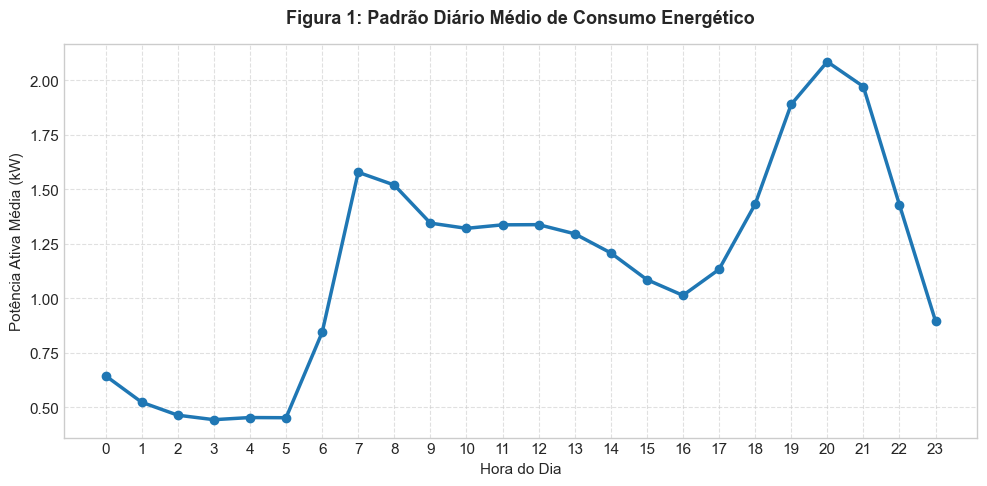

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
perfil_horario = df.groupby('Hora')['Global_active_power'].mean()
perfil_horario.plot(kind='line', ax=ax, color='#1f77b4', linewidth=2.5, marker='o')
ax.set_title('Figura 1: Padrão Diário Médio de Consumo Energético', fontsize=13, pad=15, fontweight='bold')
ax.set_xlabel('Hora do Dia', fontsize=11)
ax.set_ylabel('Potência Ativa Média (kW)', fontsize=11)
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

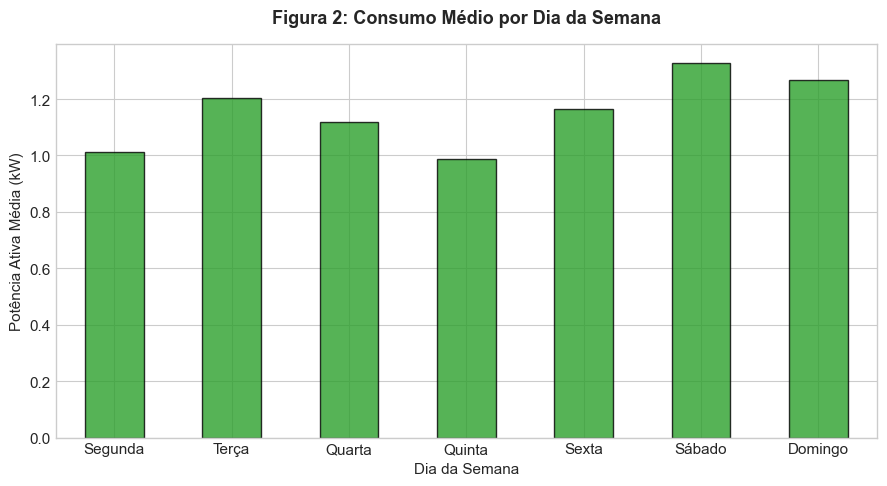

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
dias_semana = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
perfil_semanal = df.groupby(df.index.dayofweek)['Global_active_power'].mean()
perfil_semanal.index = dias_semana
perfil_semanal.plot(kind='bar', ax=ax, color='#2ca02c', edgecolor='black', alpha=0.8)
ax.set_title('Figura 2: Consumo Médio por Dia da Semana', fontsize=13, pad=15, fontweight='bold')
ax.set_xlabel('Dia da Semana', fontsize=11)
ax.set_ylabel('Potência Ativa Média (kW)', fontsize=11)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

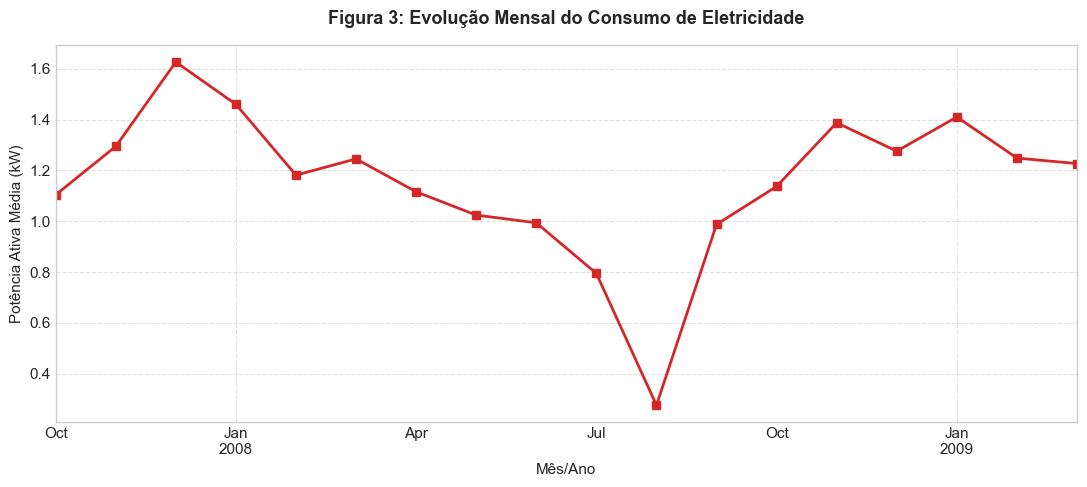

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
consumo_mensal = df.resample('ME')['Global_active_power'].mean()
consumo_mensal.plot(kind='line', ax=ax, color='#d62728', linewidth=2, marker='s')
ax.set_title('Figura 3: Evolução Mensal do Consumo de Eletricidade', fontsize=13, pad=15, fontweight='bold')
ax.set_xlabel('Mês/Ano', fontsize=11)
ax.set_ylabel('Potência Ativa Média (kW)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

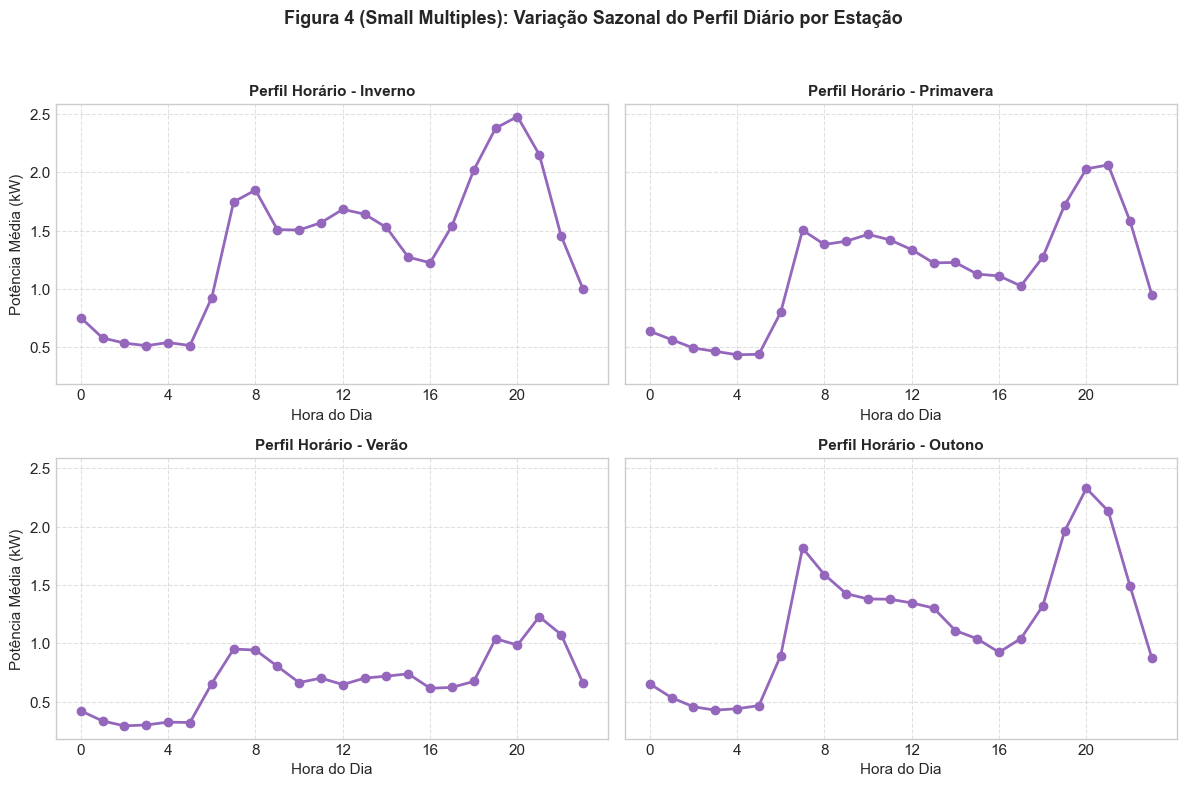

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()
estacoes = ['Inverno', 'Primavera', 'Verão', 'Outono']

for i, estacao in enumerate(estacoes):
    subset = df[df['Estacao'] == estacao]
    perfil_est = subset.groupby('Hora')['Global_active_power'].mean()
    perfil_est.plot(ax=axes[i], color='#9467bd', linewidth=2, marker='o')
    axes[i].set_title(f'Perfil Horário - {estacao}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Hora do Dia')
    axes[i].set_ylabel('Potência Média (kW)')
    axes[i].set_xticks(range(0, 24, 4))
    axes[i].grid(True, linestyle='--', alpha=0.6)

fig.suptitle('Figura 4 (Small Multiples): Variação Sazonal do Perfil Diário por Estação', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [7]:
matriz_perfis = df.pivot_table(index='Data', columns='Hora', values='Global_active_power')
matriz_perfis = matriz_perfis.dropna()

dias_validos = matriz_perfis.index
estacao_dia = df.groupby('Data')['Estacao'].first().loc[dias_validos]
util_dia = df.groupby('Data')['Dia_Util'].first().loc[dias_validos]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(matriz_perfis)

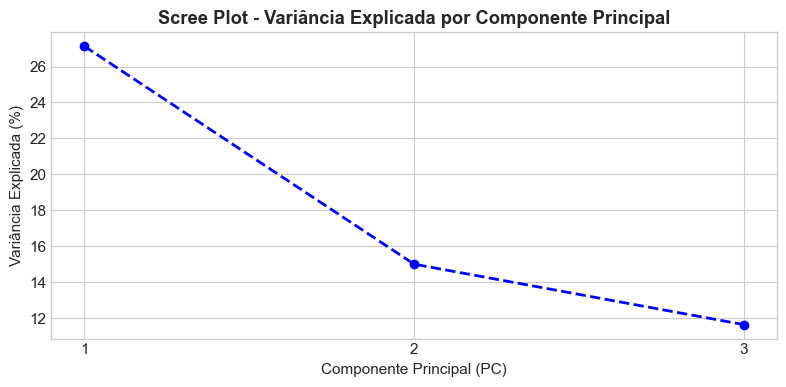

Variância explicada acumulada pelos 2 primeiros PCs: 42.13%


In [13]:
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(8, 4))
var_exp = pca.explained_variance_ratio_ * 100
ax.plot(range(1, 4), var_exp, marker='o', linestyle='--', color='b', linewidth=2)
ax.set_title('Scree Plot - Variância Explicada por Componente Principal', fontweight='bold')
ax.set_xlabel('Componente Principal (PC)')
ax.set_ylabel('Variância Explicada (%)')
ax.set_xticks([1, 2, 3])
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Variância explicada acumulada pelos 2 primeiros PCs: {var_exp[:2].sum():.2f}%")

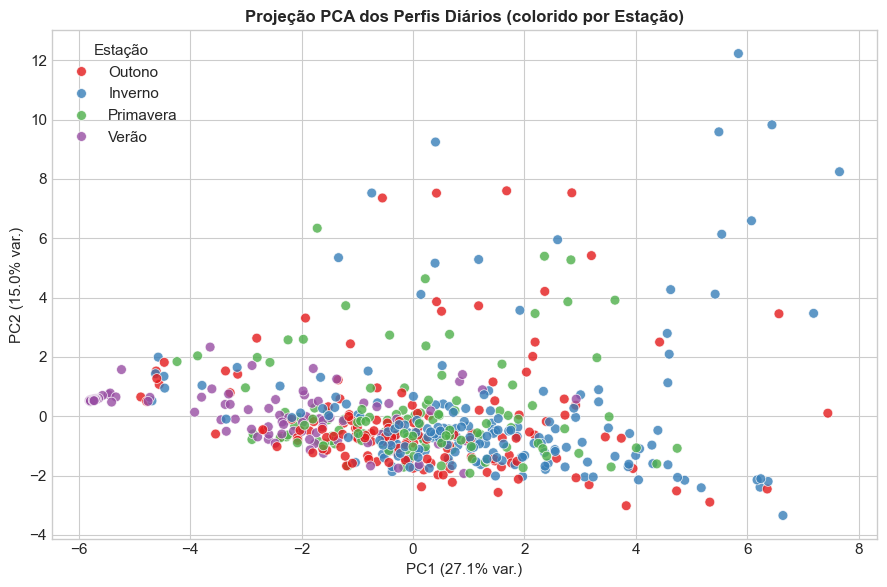

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=estacao_dia, palette='Set1', alpha=0.8, s=50, ax=ax
)
ax.set_title('Projeção PCA dos Perfis Diários (colorido por Estação)', fontsize=12, fontweight='bold')
ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}% var.)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}% var.)')
plt.legend(title='Estação')
plt.tight_layout()
plt.show()

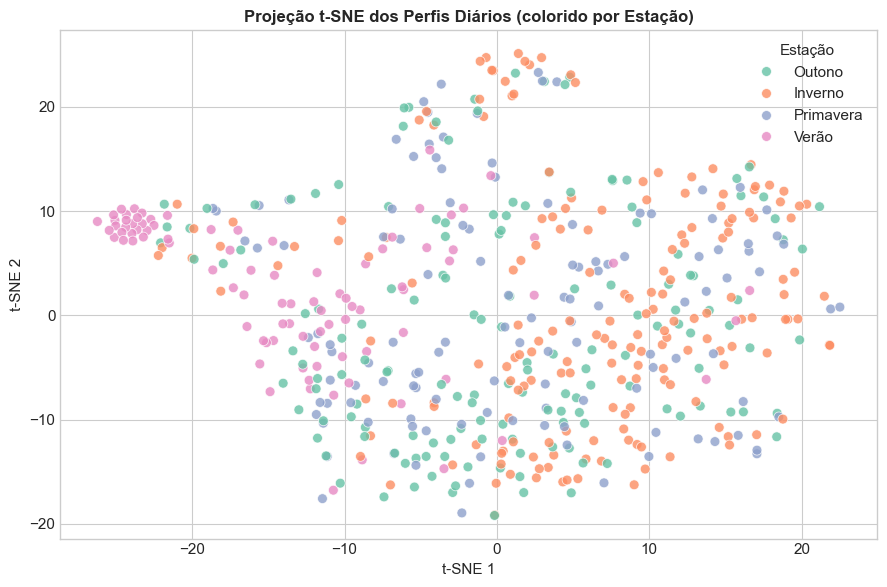

In [15]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=estacao_dia, palette='Set2', alpha=0.8, s=50, ax=ax
)
ax.set_title('Projeção t-SNE dos Perfis Diários (colorido por Estação)', fontsize=12, fontweight='bold')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.legend(title='Estação')
plt.tight_layout()
plt.show()